# Лабораторная работа №4. Байесовская сеть

### Успеваемость школьников: учебная история, планы и время занятий

В этой работе я исследовал, как сведения об ученике меняют вероятность успешной итоговой оценки. Для этого я построил байесовскую сеть, оценил её параметры и сравнил результаты при разных наблюдениях и структуре графа.

**Данные:** Student Performance · **Наблюдений:** 649 · **Переменных сети:** 5 · **Рёбер:** 7

## 1. Данные и предметная область
Для исследования я выбрал **Student Performance (UCI)**, файл `student-por.csv`: один объект — запись об ученике на курсе португальского языка в одной из двух средних школ Португалии. Это наблюдательные анкетные и школьные данные.

Источники: [страница UCI и описание переменных](https://archive.ics.uci.edu/dataset/320/student+performance), [исходный архив](https://archive.ics.uci.edu/static/public/320/student+performance.zip), DOI: [10.24432/C5TG7T](https://doi.org/10.24432/C5TG7T). Оригинальное описание сохранено в `data/student.txt`. Я рассматриваю один предмет, чтобы не объединять записи одних и тех же учеников с разных курсов.

В исходном файле есть демографические признаки, сведения о семье, учёбе, образе жизни, пропусках занятий и оценки `G1`, `G2`, `G3`. Для интерпретируемой сети я выбрал пять переменных:

| Переменная модели | Исходный столбец | Значение состояния 1 | Значение состояния 0 |
|---|---|---|---|
| education | Medu | у матери среднее/высшее образование (3–4) | образование до 9 классов включительно (0–2) |
| failures | failures | были прошлые учебные неудачи (>0) | не было (0) |
| higher | higher | хочет получить высшее образование | не хочет |
| study | studytime | занимается не менее 5 часов в неделю (3–4) | менее 5 часов (1–2) |
| passed | G3 | итоговая оценка не ниже 10 из 20 | итоговая оценка ниже 10 |

Семейная образовательная среда может быть связана с планами и учебными привычками; прошлые неудачи — с планами и итоговой оценкой; планы — с усилиями и результатом. Порог 10/20 используется как операционное определение успешного результата. Я исключил `G1` и `G2`, чтобы исследовать связь результата с учебной историей, планами и временем занятий.

In [1]:
from pathlib import Path
from itertools import product
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE = Path.cwd() if (Path.cwd() / 'data/student-por.csv').exists() else Path.cwd() / 'bayesian'
ART = BASE / 'artifacts'
ART.mkdir(exist_ok=True)

from matplotlib.ticker import PercentFormatter, MaxNLocator
from matplotlib.colors import LinearSegmentedColormap

COLORS = {'blue': '#4169A1', 'teal': '#258B83', 'orange': '#DA9561', 'red': '#BC6675', 'ink': '#26384A', 'muted': '#708395'}
plt.rcParams.update({
    'figure.figsize': (11, 4.8), 'figure.dpi': 110, 'savefig.dpi': 180,
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 13,
    'axes.titleweight': 'bold', 'axes.titlepad': 16, 'axes.labelcolor': COLORS['ink'],
    'text.color': COLORS['ink'], 'xtick.color': COLORS['muted'], 'ytick.color': COLORS['muted'],
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#D8E1E9', 'grid.color': '#E8EEF3', 'grid.alpha': 0.8,
    'axes.axisbelow': True, 'legend.frameon': False, 'figure.facecolor': 'white',
    'axes.prop_cycle': plt.cycler(color=[COLORS['blue'], COLORS['teal'], COLORS['orange'], COLORS['red']]),
})
labels = {'education': 'Образование матери', 'failures': 'Прошлые неудачи',
          'higher': 'Планы высшего образования', 'study': 'Занятия ≥ 5 ч/нед', 'passed': 'Успешная итоговая оценка'}

def save_plot(fig, name):
    fig.savefig(ART / name, bbox_inches='tight', facecolor='white')
    plt.show()

def show_table(frame):
    formats = {col: '{:.3f}' for col in frame.select_dtypes(include='floating').columns}
    display(frame.style.format(formats, na_rep='—').set_properties(**{'padding': '8px 12px', 'text-align': 'left'})
            .set_table_styles([
                {'selector': 'th', 'props': [('background-color', '#EDF3F8'), ('color', '#26384A'), ('padding', '9px 12px')]},
                {'selector': 'td', 'props': [('border-bottom', '1px solid #E8EEF3')]},
            ]))

raw = pd.read_csv(BASE / 'data/student-por.csv', sep=';')
print('Размер исходных данных:', raw.shape)
print('Пропуски:', int(raw.isna().sum().sum()))
print('Полные совпадения строк:', int(raw.duplicated().sum()))
show_table(raw[['Medu', 'failures', 'higher', 'studytime', 'G3']].head().rename(columns={'Medu': 'Образование матери', 'failures': 'Прошлые неудачи', 'higher': 'Высшее образование', 'studytime': 'Время занятий', 'G3': 'Итоговая оценка'}))

Размер исходных данных: (649, 33)
Пропуски: 0
Полные совпадения строк: 0


,Образование матери,Прошлые неудачи,Высшее образование,Время занятий,Итоговая оценка
0,4,0,yes,2,11
1,1,0,yes,2,11
2,1,0,yes,2,12
3,4,0,yes,3,14
4,3,0,yes,2,13


### Распределение итоговых оценок

Сначала я рассмотрел исходную шкалу оценок и положение выбранного порога успешности.

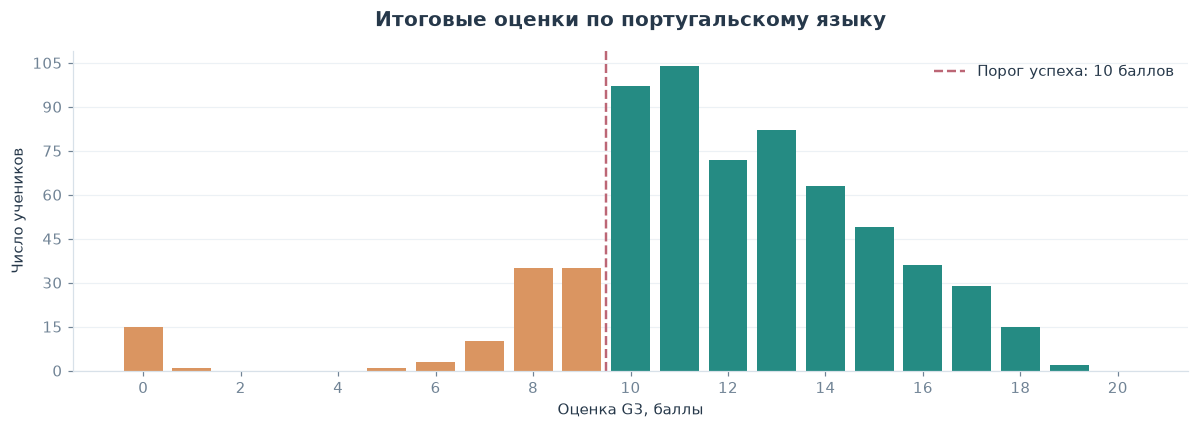

In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
counts = raw.G3.value_counts().reindex(range(21), fill_value=0)
ax.bar(counts.index, counts.values, color=[COLORS['orange'] if x < 10 else COLORS['teal'] for x in counts.index], width=0.8)
ax.axvline(9.5, color=COLORS['red'], linestyle='--', linewidth=1.6, label='Порог успеха: 10 баллов')
ax.set(title='Итоговые оценки по португальскому языку', xlabel='Оценка G3, баллы', ylabel='Число учеников', xticks=range(0, 21, 2))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis='y')
ax.legend()
fig.tight_layout()
save_plot(fig, 'grades_distribution.png')

## 2. Подготовка данных
`Medu` и `studytime` уже закодированы порядковыми категориями: не следует считать расстояния между их кодами равными. Я объединил соседние уровни по смыслу. Прошлые неудачи я перевёл в индикатор: отдельные большие значения слишком редки для оценки многомерных CPT. Оценку `G3` я дискретизировал по порогу 10 баллов. Нулевые оценки `G3` я сохранил как наблюдаемые результаты.

Каждая переменная имеет два состояния, поэтому полное совместное распределение содержит всего 32 комбинации. Все наблюдения я использовал для описательной оценки вероятностей. Перед преобразованием я проверил пропуски и допустимые значения признаков. Совпадение характеристик не доказывает повторную запись одного ученика, поэтому я не удалял совпадающие строки автоматически.

In [3]:
assert not raw.isna().any().any(), 'Нужно отдельно исследовать появившиеся пропуски'
for col, values in {'Medu': range(5), 'studytime': range(1, 5),
                    'failures': range(5), 'higher': ['yes', 'no'], 'G3': range(21)}.items():
    assert raw[col].isin(values).all(), col
data = pd.DataFrame({
    'education': (raw.Medu >= 3).astype(int),
    'failures': (raw.failures > 0).astype(int),
    'higher': raw.higher.map({'no': 0, 'yes': 1}),
    'study': (raw.studytime >= 3).astype(int),
    'passed': (raw.G3 >= 10).astype(int),
})
nodes = list(data.columns)
frequencies = pd.DataFrame({v: data[v].value_counts().reindex([0, 1], fill_value=0) for v in nodes}).T
frequencies.columns = ['n(0)', 'n(1)']
frequencies['доля состояния 1'] = data.mean()
show_table(frequencies)
frequencies.to_csv(ART / 'frequencies.csv')
data.to_csv(ART / 'prepared_data.csv', index=False)

,n(0),n(1),доля состояния 1
education,335,314,0.484
failures,549,100,0.154
higher,69,580,0.894
study,517,132,0.203
passed,100,549,0.846


### Баланс состояний

После дискретизации я сравнил частоты состояний. Дисбаланс особенно заметен для планов высшего образования и итоговой оценки.

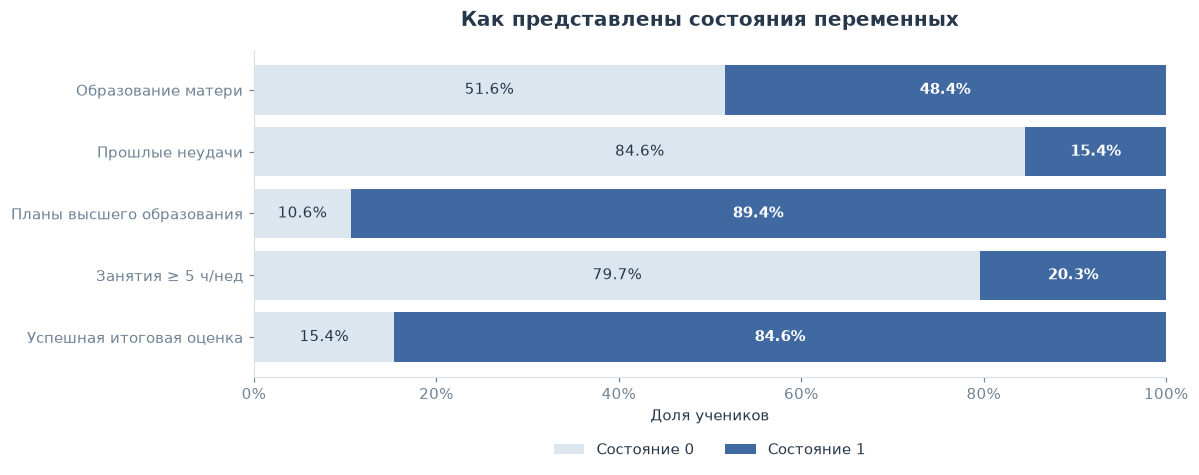

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
y = np.arange(len(nodes))
p1 = data.mean().to_numpy()
ax.barh(y, 1-p1, color='#DCE6EF', label='Состояние 0')
ax.barh(y, p1, left=1-p1, color=COLORS['blue'], label='Состояние 1')
for i, value in enumerate(p1):
    ax.text((1-value)/2, i, f'{1-value:.1%}', ha='center', va='center', color=COLORS['ink'])
    ax.text(1-value/2, i, f'{value:.1%}', ha='center', va='center', color='white', fontweight='bold')
ax.set(yticks=y, yticklabels=[labels[v] for v in nodes], xlim=(0, 1), title='Как представлены состояния переменных', xlabel='Доля учеников')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout()
save_plot(fig, 'state_balance.png')

## 3. Вопросы исследования
1. Как меняется вероятность успешного результата, если известно, что у ученика были прошлые учебные неудачи?
2. Какова вероятность успешного результата при прошлых неудачах и желании получить высшее образование?
3. Как меняется эта вероятность, если дополнительно известно о занятиях не менее пяти часов в неделю?
4. Как знание об успешном результате меняет вероятность того, что ученик хочет получить высшее образование? Это обратный диагностический вывод.

Для каждого вопроса я сравнил безусловную вероятность с условной. В первых трёх случаях я также проследил последовательное изменение распределения `passed`.

## 4. Структура байесовской сети
Направления рёбер я выбрал по смыслу переменных до оценки условных вероятностей:

| Ребро | Обоснование зависимости и направления |
|---|---|
| education → higher | Образовательная среда семьи предшествует формированию планов ученика. |
| education → study | Семейные образовательные привычки могут быть связаны с временем занятий. |
| failures → higher | Прошлые неудачи могут быть связаны с последующим пересмотром планов. |
| higher → study | Учебные планы могут определять текущие усилия; обратное направление тоже правдоподобно. |
| failures → passed | Прошлые трудности предшествуют итоговой оценке и несут сведения о подготовке. |
| higher → passed | Планы могут отражать мотивацию и особенности подготовки сверх часов занятий. |
| study → passed | Затраченное на подготовку время может быть связано с последующим результатом. |

Это **модель статистических зависимостей**, а объяснения направлений — гипотезы. Время измерения анкетных признаков не позволяет установить строгую причинную последовательность. Удалённые из модели факторы (способности, доход, школа) могут создавать смешение.

Факторизация:

`P(E,F,H,S,Y) = P(E) P(F) P(H|E,F) P(S|E,H) P(Y|F,H,S)`.

Например, модель предполагает независимость корней E и F, а также `Y ⟂ E | F,H,S`. Это упрощения, которые не следуют автоматически из данных.

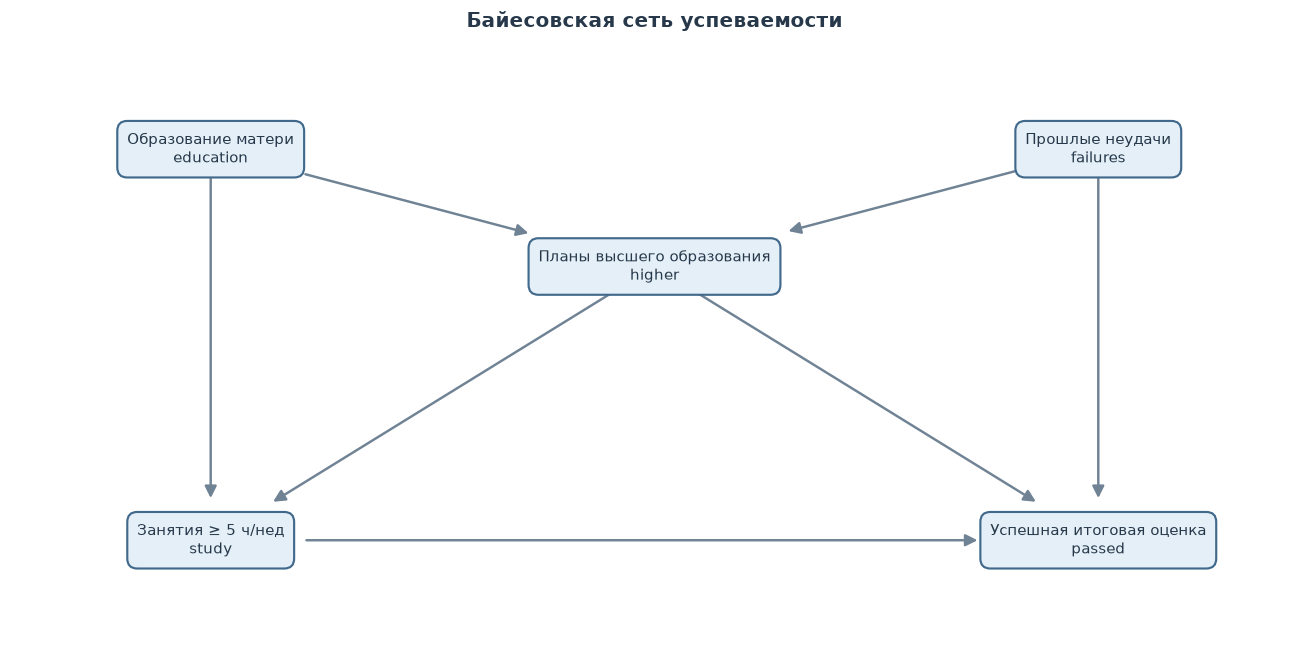

DAG проверен; число свободных параметров: 18


In [5]:
parents = {
    'education': [], 'failures': [],
    'higher': ['education', 'failures'],
    'study': ['education', 'higher'],
    'passed': ['failures', 'higher', 'study'],
}
def check_dag(structure):
    done = set()
    while len(done) < len(structure):
        ready = {v for v, ps in structure.items() if v not in done and set(ps) <= done}
        if not ready:
            raise ValueError('Граф содержит цикл или неизвестную вершину')
        done |= ready
check_dag(parents)
positions = {'education': (0, 2), 'failures': (4, 2), 'higher': (2, 1.4),
             'study': (0, 0), 'passed': (4, 0)}
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 6))
ax.set(xlim=(-0.9, 4.9), ylim=(-0.5, 2.5), title='Байесовская сеть успеваемости')
ax.axis('off')
node_texts = {}
for node, (x, y) in positions.items():
    node_texts[node] = ax.text(x, y, labels[node] + '\n' + node, ha='center', va='center', zorder=3,
        bbox=dict(boxstyle='round,pad=0.65', fc='#E4EFF7', ec='#41698B', linewidth=1.4))
fig.tight_layout()
fig.canvas.draw()
for child, ps in parents.items():
    for parent in ps:
        arrow = FancyArrowPatch(positions[parent], positions[child],
            patchA=node_texts[parent].get_bbox_patch(), patchB=node_texts[child].get_bbox_patch(),
            arrowstyle='-|>', mutation_scale=16, linewidth=1.6, color='#708395',
            shrinkA=4, shrinkB=5, zorder=2)
        ax.add_patch(arrow)
fig.tight_layout()
fig.savefig(ART / 'network.png', dpi=160)
plt.show()
print('DAG проверен; число свободных параметров:', sum(2 ** len(ps) for ps in parents.values()))

## 5. Оценка таблиц условных вероятностей
Для оценки параметров я использовал симметричное сглаживание Лапласа (псевдосчётчик **α=1 для каждого состояния в каждой строке CPT**):

`P(X=x | Pa=u) = (N(X=x, Pa=u) + α) / (N(Pa=u) + 2α)`.

Это апостериорное среднее при независимом априорном распределении Dirichlet(1,1) для каждой строки. Оно исключает нулевые вероятности; для пустой родительской комбинации даёт 0.5/0.5. Для точного вывода я реализовал перебор всех 32 состояний сети.

Я сопоставил CPT с несглаженными частотами и численностью родительских групп. Небольшие группы ограничивают точность независимо от общего объёма данных.

In [6]:
def fit_cpts(frame, structure, alpha=1.0):
    check_dag(structure)
    if alpha <= 0:
        raise ValueError('Для данной реализации alpha должно быть положительным')
    tables = {}
    for node, ps in structure.items():
        rows = []
        for values in product([0, 1], repeat=len(ps)):
            mask = np.ones(len(frame), dtype=bool)
            for p, value in zip(ps, values):
                mask &= frame[p].to_numpy() == value
            total = int(mask.sum())
            n1 = int(frame.loc[mask, node].sum())
            p1 = (n1 + alpha) / (total + 2 * alpha)
            rows.append(dict(zip(ps, values), n=total, n1=n1,
                             empirical_p1=n1 / total if total else np.nan,
                             p0=1-p1, p1=p1))
        tables[node] = pd.DataFrame(rows)
    return tables

cpts = fit_cpts(data, parents)
for node, table in cpts.items():
    print(f'P({node}=1 | {parents[node]}):')
    show_table(table.round(4))
    table.to_csv(ART / f'cpt_{node}.csv', index=False)
print('Родительские группы с n < 10:')
display(pd.concat([t.assign(node=v) for v, t in cpts.items()], ignore_index=True).query('n < 10'))

for node, table in cpts.items():
    assert table.n.sum() == len(data)
    assert np.allclose(table.p0 + table.p1, 1)
    assert table[['p0', 'p1']].gt(0).all().all()

def joint_distribution(structure, tables):
    joint = pd.DataFrame(product([0, 1], repeat=len(structure)), columns=list(structure))
    probs = []
    for _, state in joint.iterrows():
        prob = 1.0
        for node, ps in structure.items():
            table = tables[node]
            mask = np.ones(len(table), dtype=bool)
            for p in ps:
                mask &= table[p].to_numpy() == state[p]
            row = table.loc[mask].iloc[0]
            prob *= row['p1' if state[node] else 'p0']
        probs.append(prob)
    joint['probability'] = probs
    assert np.isclose(joint.probability.sum(), 1), 'Совместное распределение не нормировано'
    return joint

joint = joint_distribution(parents, cpts)

def query(variable, evidence=None, distribution=None):
    dist = joint if distribution is None else distribution
    evidence = {} if evidence is None else evidence
    if variable not in nodes or any(k not in nodes or v not in [0, 1] for k, v in evidence.items()):
        raise ValueError('Неизвестная переменная или состояние')
    mask = np.ones(len(dist), dtype=bool)
    for node, value in evidence.items():
        mask &= dist[node].to_numpy() == value
    subset = dist.loc[mask]
    normalizer = subset.probability.sum()
    if normalizer <= 0:
        raise ValueError('Evidence имеет нулевую вероятность')
    return subset.groupby(variable).probability.sum().reindex([0, 1], fill_value=0) / normalizer

marginals = pd.DataFrame({'эмпирическая доля': data.mean(),
                         'маргинальная вероятность сети': {v: query(v)[1] for v in nodes}})
marginals['разница, п.п.'] = 100 * (marginals.iloc[:, 1] - marginals.iloc[:, 0])
show_table(marginals.round(4))
marginals.to_csv(ART / 'marginals.csv')

P(education=1 | []):


,n,n1,empirical_p1,p0,p1
0,649,314,0.484,0.516,0.484


P(failures=1 | []):


,n,n1,empirical_p1,p0,p1
0,649,100,0.154,0.845,0.155


P(higher=1 | ['education', 'failures']):


,education,failures,n,n1,empirical_p1,p0,p1
0,0,0,266,237,0.891,0.112,0.888
1,0,1,69,43,0.623,0.380,0.620
2,1,0,283,276,0.975,0.028,0.972
3,1,1,31,24,0.774,0.242,0.758


... (3 outputs left out)

,failures,higher,study,n,n1,empirical_p1,p0,p1
0,0,0,0,32,20,0.625,0.382,0.618
1,0,0,1,4,2,0.500,0.500,0.500
2,0,1,0,395,360,0.911,0.091,0.909
3,0,1,1,118,116,0.983,0.025,0.975
4,1,0,0,31,13,0.419,0.576,0.424
5,1,0,1,2,1,0.500,0.500,0.500
6,1,1,0,59,33,0.559,0.443,0.557
7,1,1,1,8,4,0.500,0.500,0.500


Родительские группы с n < 10:


,n,n1,empirical_p1,p0,p1,node,education,failures,higher,study
11,4,2,0.5,0.5,0.5,passed,NaN,0.0,0.0,1.0
15,2,1,0.5,0.5,0.5,passed,NaN,1.0,0.0,1.0
17,8,4,0.5,0.5,0.5,passed,NaN,1.0,1.0,1.0


,эмпирическая доля,маргинальная вероятность сети,"разница, п.п."
education,0.484,0.484,0.005
failures,0.154,0.155,0.106
higher,0.894,0.891,-0.262
study,0.203,0.208,0.476
passed,0.846,0.840,-0.555


### Вероятность успеха и численность родительских групп

Я сопоставил строки CPT на тепловой карте. В каждой ячейке указаны вероятность успеха и число наблюдений: высокая оценка при малом `n` требует осторожной интерпретации.

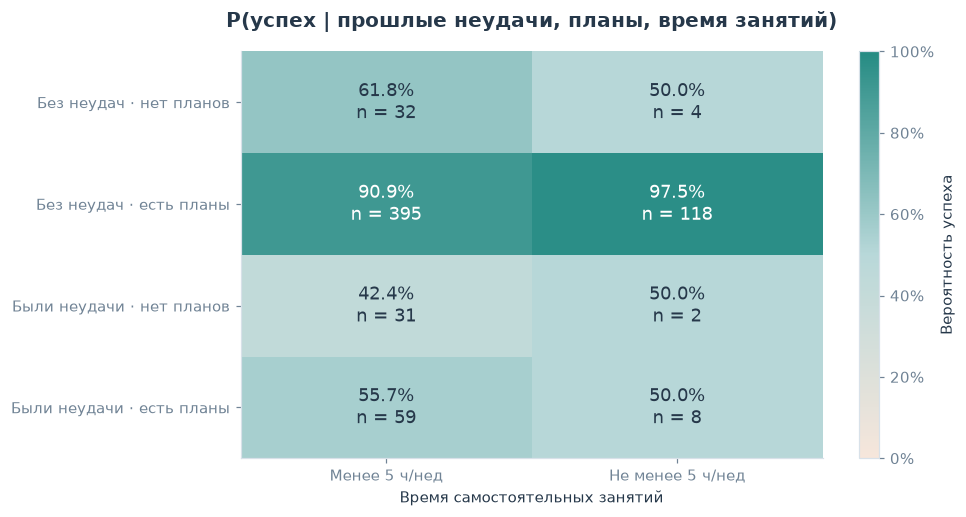

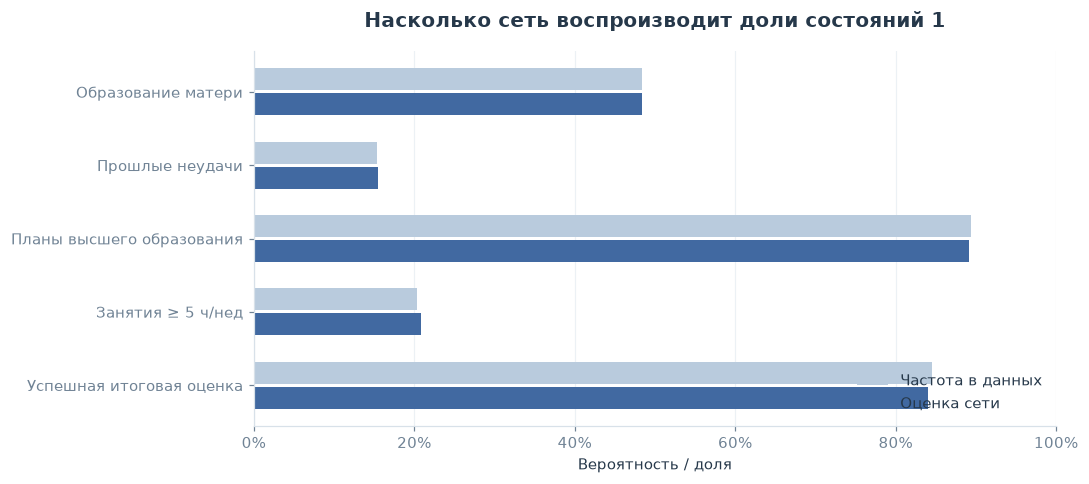

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.8))
row_keys = [(0, 0), (0, 1), (1, 0), (1, 1)]
table = cpts['passed'].set_index(['failures', 'higher', 'study'])
values = np.array([[table.loc[(f, h, s), 'p1'] for s in [0, 1]] for f, h in row_keys])
cmap = LinearSegmentedColormap.from_list('success', ['#F6E6DB', '#B8D8D9', '#258B83'])
im = ax.imshow(values, cmap=cmap, vmin=0, vmax=1, aspect='auto')
for i, (f, h) in enumerate(row_keys):
    for s in [0, 1]:
        row = table.loc[(f, h, s)]
        ax.text(s, i, f"{row.p1:.1%}\nn = {int(row.n)}", ha='center', va='center',
                color='white' if row.p1 > 0.75 else COLORS['ink'], fontsize=12)
ax.set(xticks=[0, 1], xticklabels=['Менее 5 ч/нед', 'Не менее 5 ч/нед'],
       yticks=range(4), yticklabels=['Без неудач · нет планов', 'Без неудач · есть планы', 'Были неудачи · нет планов', 'Были неудачи · есть планы'],
       title='P(успех | прошлые неудачи, планы, время занятий)', xlabel='Время самостоятельных занятий')
fig.colorbar(im, ax=ax, format=PercentFormatter(1), label='Вероятность успеха')
fig.tight_layout()
save_plot(fig, 'cpt_success_heatmap.png')

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(nodes))
ax.barh(y-0.17, marginals.iloc[:, 0], height=0.3, label='Частота в данных', color='#B9CBDD')
ax.barh(y+0.17, marginals.iloc[:, 1], height=0.3, label='Оценка сети', color=COLORS['blue'])
ax.set(yticks=y, yticklabels=[labels[v] for v in nodes], xlim=(0, 1), title='Насколько сеть воспроизводит доли состояний 1', xlabel='Вероятность / доля')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis='x')
ax.invert_yaxis()
ax.legend(loc='lower right')
fig.tight_layout()
save_plot(fig, 'marginals_comparison.png')

Несглаженные частоты в каждой строке CPT непосредственно получены из соответствующей подвыборки; расхождение с оценкой вызвано псевдосчётчиками. Маргинальные вероятности сети могут дополнительно отличаться от частот из-за ограничений факторизации: произведение локальных CPT не обязано воспроизводить произвольное эмпирическое распределение.

Отдельно я рассмотрел самую малочисленную родительскую группу целевой переменной. Её значение особенно чувствительно к сглаживанию; редкое сочетание признаков не даёт оснований для уверенного предметного вывода.

In [8]:
smallest = cpts['passed'].sort_values('n').iloc[0]
display(Markdown(
    f"Минимальная группа CPT `passed`: failures={int(smallest.failures)}, "
    f"higher={int(smallest.higher)}, study={int(smallest.study)}, **n={int(smallest.n)}**. "
    f"Вероятность успеха после сглаживания — **{smallest.p1:.1%}**. "
    "Если группа пуста, её оценка полностью определяется априорным распределением; "
    "при нескольких наблюдениях крайние частоты также нельзя считать устойчивой закономерностью."
))
display(pd.crosstab([data.failures, data.higher], data.passed, normalize='index').round(3))

Минимальная группа CPT `passed`: failures=1, higher=0, study=1, **n=2**. Вероятность успеха после сглаживания — **50.0%**. Если группа пуста, её оценка полностью определяется априорным распределением; при нескольких наблюдениях крайние частоты также нельзя считать устойчивой закономерностью.

passed               0      1
failures higher              
0        0       0.389  0.611
         1       0.072  0.928
1        0       0.576  0.424
         1       0.448  0.552

## 6. Вероятностный вывод: ответы на вопросы
Я вычислил `P(Q | evidence)` суммированием совместных вероятностей совместимых состояний с последующей нормировкой. Я также сопоставил оценки сети с прямыми частотами и числом наблюдений в каждой группе.

In [9]:
questions = [
    ('1. Прошлые неудачи', 'passed', {'failures': 1}),
    ('2. Неудачи и планы', 'passed', {'failures': 1, 'higher': 1}),
    ('3. Дополнительно ≥5 ч/нед', 'passed', {'failures': 1, 'higher': 1, 'study': 1}),
    ('4. Обратный вывод по успеху', 'higher', {'passed': 1}),
]
rows = []
for name, target, evidence in questions:
    mask = np.ones(len(data), dtype=bool)
    for node, value in evidence.items():
        mask &= data[node].to_numpy() == value
    before, after = float(query(target)[1]), float(query(target, evidence)[1])
    rows.append({'вопрос': name, 'цель': target, 'evidence': str(evidence),
                 'P до': before, 'P после': after, 'Δ, п.п.': 100*(after-before),
                 'n evidence': int(mask.sum()), 'частота в данных': data.loc[mask, target].mean()})
answers = pd.DataFrame(rows)
show_table(answers.round(4))
answers.to_csv(ART / 'queries.csv', index=False)
for row in rows:
    direction = 'выше' if row['P после'] > row['P до'] else 'ниже'
    display(Markdown(f"**{row['вопрос']}**: вероятность `{row['цель']}=1` равна "
                     f"{row['P после']:.1%} против {row['P до']:.1%} без информации "
                     f"({direction} на {abs(row['Δ, п.п.']):.2f} п.п.). "
                     f"В исходных данных это сочетание встречается {row['n evidence']} раз."))

,вопрос,цель,evidence,P до,P после,"Δ, п.п.",n evidence,частота в данных
0,1. Прошлые неудачи,passed,{'failures': 1},0.840,0.510,-33.012,100,0.510
1,2. Неудачи и планы,passed,"{'failures': 1, 'higher': 1}",0.840,0.545,-29.558,67,0.552
2,3. Дополнительно ≥5 ч/нед,passed,"{'failures': 1, 'higher': 1, 'study': 1}",0.840,0.500,-34.036,8,0.500
3,4. Обратный вывод по успеху,higher,{'passed': 1},0.891,0.931,4.035,549,0.934


**1. Прошлые неудачи**: вероятность `passed=1` равна 51.0% против 84.0% без информации (ниже на 33.01 п.п.). В исходных данных это сочетание встречается 100 раз.

**2. Неудачи и планы**: вероятность `passed=1` равна 54.5% против 84.0% без информации (ниже на 29.56 п.п.). В исходных данных это сочетание встречается 67 раз.

**3. Дополнительно ≥5 ч/нед**: вероятность `passed=1` равна 50.0% против 84.0% без информации (ниже на 34.04 п.п.). В исходных данных это сочетание встречается 8 раз.

**4. Обратный вывод по успеху**: вероятность `higher=1` равна 93.1% против 89.1% без информации (выше на 4.03 п.п.). В исходных данных это сочетание встречается 549 раз.

### Обновление вероятностей

Для каждого запроса я показал переход от базовой вероятности к условной. Последняя строка относится к планам высшего образования; первые три — к успешному результату.

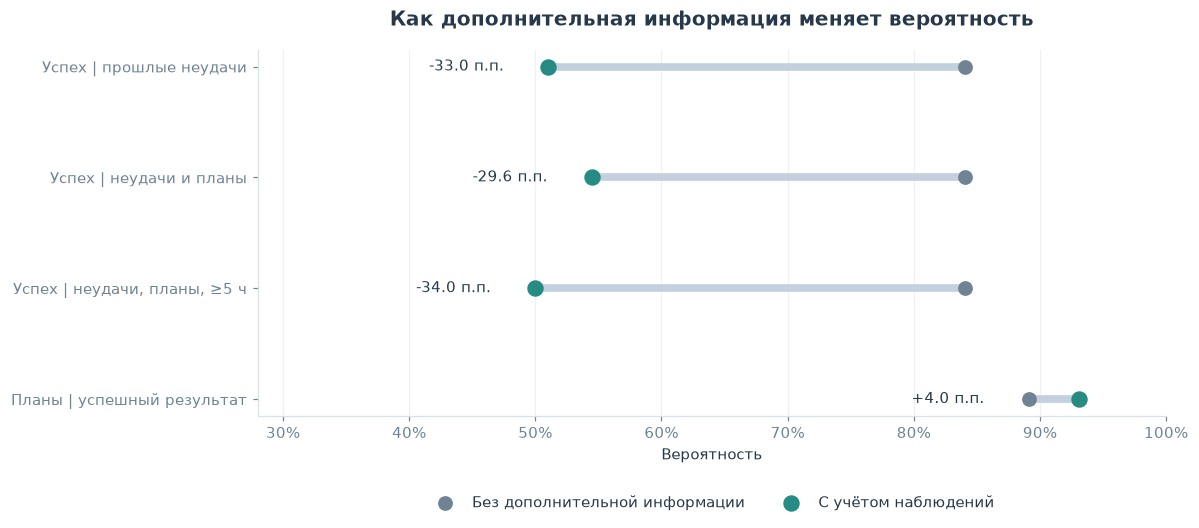

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(answers))
for i, row in answers.iterrows():
    ax.plot([row['P до'], row['P после']], [i, i], color='#C3D0DE', lw=5, solid_capstyle='round')
    ax.text(min(row['P до'], row['P после'])-0.035, i, f"{row['Δ, п.п.']:+.1f} п.п.", va='center', ha='right', fontsize=10)
ax.scatter(answers['P до'], y, color=COLORS['muted'], s=75, label='Без дополнительной информации', zorder=3)
ax.scatter(answers['P после'], y, color=COLORS['teal'], s=95, label='С учётом наблюдений', zorder=4)
ax.set(yticks=y, yticklabels=['Успех | прошлые неудачи', 'Успех | неудачи и планы', 'Успех | неудачи, планы, ≥5 ч', 'Планы | успешный результат'],
       xlim=(0.28, 1), title='Как дополнительная информация меняет вероятность', xlabel='Вероятность')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
ax.grid(axis='x')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout()
save_plot(fig, 'query_updates.png')

**Разбор необычного результата.** При `failures=1, higher=1` добавление `study=1` снижает оценку примерно с 54.48% до 50%. В группе с длительными занятиями только **8 учеников и 4 успеха**; с меньшим временем — **59 учеников и 33 успеха**. Напротив, среди учеников без прошлых неудач и с планами высшего образования доля успехов растёт с **360/395 ≈ 91.14%** до **116/118 ≈ 98.31%**. Возможные объяснения различия — случайные колебания малой группы, различия в подготовке и обратный отбор (испытывающие трудности ученики занимаются больше). По этим данным выбрать одно объяснение нельзя; вывод «длительные занятия вредят» не обоснован.

### Почему важно учитывать размер группы

Я отдельно сравнил учеников с планами высшего образования. Подписи показывают число успехов и размер каждой подгруппы; интервалы отражают неопределённость эмпирических долей (95% интервал Уилсона), а не неопределённость параметров всей сети.

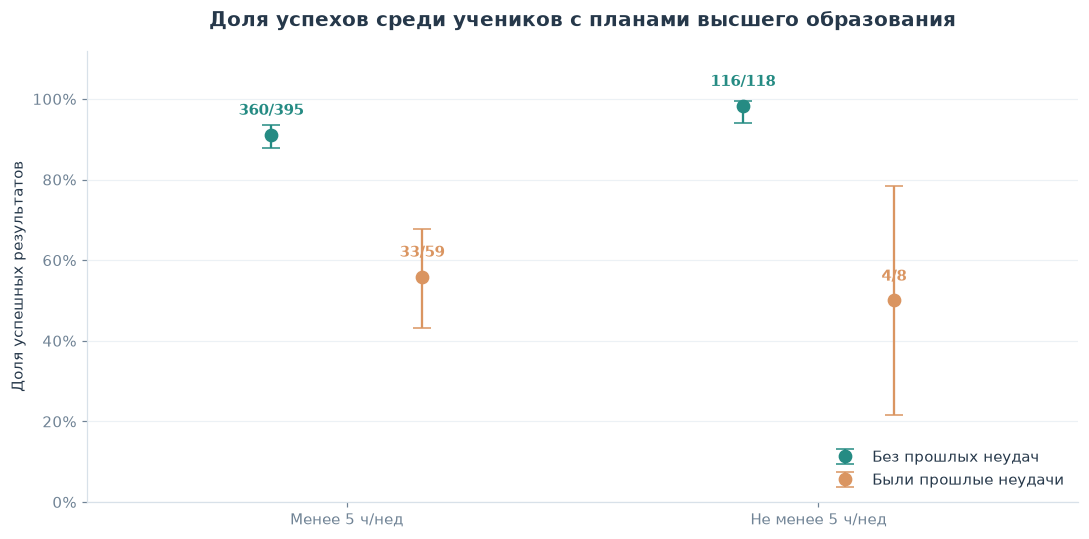

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
z = 1.959963984540054
for f, offset, color, label in [(0, -0.16, COLORS['teal'], 'Без прошлых неудач'), (1, 0.16, COLORS['orange'], 'Были прошлые неудачи')]:
    for s in [0, 1]:
        group = data[(data.failures == f) & (data.higher == 1) & (data.study == s)]
        total, successes = len(group), int(group.passed.sum())
        rate = successes / total
        center = (rate + z*z/(2*total)) / (1+z*z/total)
        half = z*np.sqrt(rate*(1-rate)/total + z*z/(4*total*total)) / (1+z*z/total)
        ax.errorbar(s+offset, rate, yerr=[[rate-center+half], [center+half-rate]], fmt='o', capsize=6,
                    markersize=8, color=color, label=label if s == 0 else None)
        ax.annotate(f'{successes}/{total}', (s+offset, rate), xytext=(0, 13), textcoords='offset points', ha='center', color=color, fontweight='bold')
ax.set(xticks=[0, 1], xticklabels=['Менее 5 ч/нед', 'Не менее 5 ч/нед'], ylim=(0, 1.12), xlim=(-0.55, 1.55),
       title='Доля успехов среди учеников с планами высшего образования', ylabel='Доля успешных результатов')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis='y')
ax.legend(loc='lower right')
fig.tight_layout()
save_plot(fig, 'study_subgroups.png')

Первый запрос характеризует связь прежних трудностей с текущим результатом. Второй уточняет профиль ученика через его планы; сравнение с первым запросом описывает добавочную информацию, а не эффект назначения высшего образования. Третий выделяет более узкую группу: знак изменения может зависеть от её малого размера и отбора учеников. Четвёртый показывает диагностический вывод от результата к связанным с ним планам: вероятность причины/предиктора можно обновлять по наблюдаемому следствию, не обращая стрелку графа.

## 7. Последовательное добавление evidence
В качестве целевой переменной я выбрал `passed`. Затем я последовательно добавлял сведения о прошлых неудачах, планах высшего образования и времени занятий. На графике я сопоставил оба состояния результата и изменение вероятности успеха между этапами.

,P(неуспех),P(успех),"Δ успеха к предыдущему, п.п."
этап,,,
Ничего не известно,0.160,0.840,—
F=1,0.490,0.510,-33.012
"F=1, H=1",0.455,0.545,3.453
"F=1, H=1, S=1",0.500,0.500,-4.478


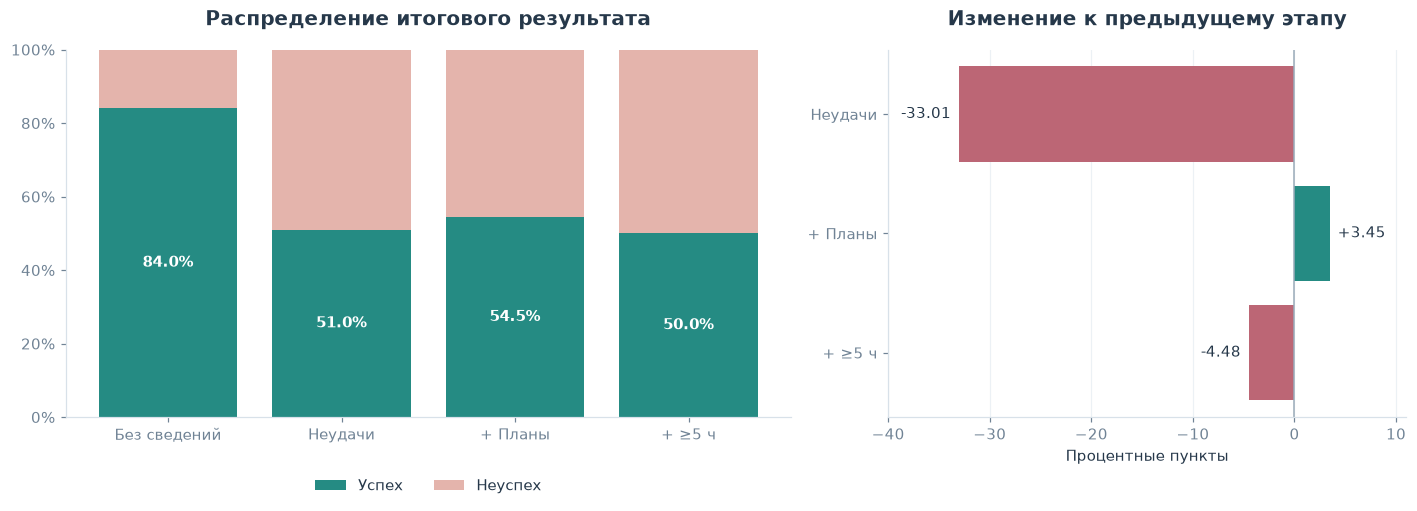

На этапе **F=1** дополнительная информация меняет вероятность успеха на **-33.01 п.п.** относительно предыдущего этапа.

На этапе **F=1, H=1** дополнительная информация меняет вероятность успеха на **+3.45 п.п.** относительно предыдущего этапа.

На этапе **F=1, H=1, S=1** дополнительная информация меняет вероятность успеха на **-4.48 п.п.** относительно предыдущего этапа.

In [12]:
steps = [('Ничего не известно', {}), ('F=1', {'failures': 1}),
         ('F=1, H=1', {'failures': 1, 'higher': 1}),
         ('F=1, H=1, S=1', {'failures': 1, 'higher': 1, 'study': 1})]
evidence_table = pd.DataFrame([
    {'этап': label, 'P(неуспех)': query('passed', ev)[0], 'P(успех)': query('passed', ev)[1]}
    for label, ev in steps
]).set_index('этап')
evidence_table['Δ успеха к предыдущему, п.п.'] = evidence_table['P(успех)'].diff() * 100
show_table(evidence_table.round(4))
evidence_table.to_csv(ART / 'evidence.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.4, 1]})
x = np.arange(len(evidence_table))
p = evidence_table['P(успех)'].to_numpy()
axes[0].bar(x, p, color=COLORS['teal'], label='Успех')
axes[0].bar(x, 1-p, bottom=p, color='#E4B4AC', label='Неуспех')
for i, value in enumerate(p):
    axes[0].text(i, value/2, f'{value:.1%}', ha='center', va='center', color='white', fontweight='bold')
axes[0].set(xticks=x, xticklabels=['Без сведений', 'Неудачи', '+ Планы', '+ ≥5 ч'], ylim=(0, 1), title='Распределение итогового результата')
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2)
deltas = evidence_table.iloc[1:, 2].to_numpy()
bars = axes[1].barh(range(3), deltas, color=[COLORS['teal'] if d > 0 else COLORS['red'] for d in deltas])
axes[1].axvline(0, color='#9AABB9', lw=1)
for bar, value in zip(bars, deltas):
    axes[1].text(value + (0.8 if value >= 0 else -0.8), bar.get_y()+bar.get_height()/2,
                 f'{value:+.2f}', ha='left' if value >= 0 else 'right', va='center')
axes[1].set(yticks=range(3), yticklabels=['Неудачи', '+ Планы', '+ ≥5 ч'], xlim=(-40, 11), title='Изменение к предыдущему этапу', xlabel='Процентные пункты')
axes[1].invert_yaxis()
axes[1].grid(axis='x')
fig.tight_layout()
save_plot(fig, 'evidence.png')
for i in range(1, len(evidence_table)):
    delta = evidence_table.iloc[i, 2]
    display(Markdown(f"На этапе **{evidence_table.index[i]}** дополнительная информация "
                     f"меняет вероятность успеха на **{delta:+.2f} п.п.** относительно предыдущего этапа."))

Все три наблюдаемые переменные являются родителями `passed`. Сначала `failures` влияет как напрямую, так и через распределения `higher` и `study`. Когда известен `higher`, исчезает необходимость усреднять по его состояниям, но `study` ещё неизвестен. После наблюдения всех родителей распределение `passed` совпадает с одной строкой CPT. Я проверил это численно. Информация не обязана монотонно увеличивать вероятность успеха: направление обновления определяется значениями evidence и оценёнными таблицами.

In [13]:
specific = cpts['passed'].query('failures == 1 and higher == 1 and study == 1').iloc[0]
assert np.isclose(query('passed', steps[-1][1])[1], specific.p1)

for target in nodes:
    assert np.isclose(query(target).sum(), 1)
    for evidence_node in nodes:
        if evidence_node != target:
            reconstructed = sum(query(target, {evidence_node: x})[1] * query(evidence_node)[x] for x in [0, 1])
            assert np.isclose(reconstructed, query(target)[1])
print('Нормировка, CPT при полностью известных родителях и закон полной вероятности: OK')

Нормировка, CPT при полностью известных родителях и закон полной вероятности: OK


## 8. Эксперимент со структурой
Я удалил ребро **failures → passed** и повторно оценил CPT на тех же данных с прежним значением α. Теперь прошлые неудачи не имеют прямого канала к результату, но сохраняется косвенный путь через планы и занятия. Затем я сравнил третий запрос и базовую вероятность. При фиксированных `higher` и `study` оставшиеся пути от `failures` к `passed` блокируются: модифицированная сеть утверждает `passed ⟂ failures | higher, study`. В исходной сети этой независимости нет.

In [14]:
reduced_parents = {v: list(ps) for v, ps in parents.items()}
reduced_parents['passed'].remove('failures')
reduced_cpts = fit_cpts(data, reduced_parents)
reduced_joint = joint_distribution(reduced_parents, reduced_cpts)
structure_result = pd.DataFrame([
    {'структура': name,
     'P(успех)': query('passed', distribution=dist)[1],
     'P(успех | F=1,H=1,S=1)': query('passed', steps[-1][1], dist)[1]}
    for name, dist in [('Исходная', joint), ('Без failures → passed', reduced_joint)]
]).set_index('структура')
show_table(structure_result.round(4))
structure_result.to_csv(ART / 'structure_comparison.csv')
delta_structure = 100 * (structure_result.iloc[1, 1] - structure_result.iloc[0, 1])
display(Markdown(f"После удаления ребра условная вероятность меняется на **{delta_structure:+.2f} п.п.**. "
                 "CPT результата теперь объединяет учеников с прошлыми неудачами и без них при одинаковых планах и часах занятий. "
                 "Поэтому информация о неудачах теряет самостоятельный вклад в данном запросе."))
assert np.isclose(query('passed', {'failures': 0, 'higher': 1, 'study': 1}, reduced_joint)[1],
                  query('passed', {'failures': 1, 'higher': 1, 'study': 1}, reduced_joint)[1])
print('Условная независимость после удаления ребра проверена.')

,P(успех),"P(успех | F=1,H=1,S=1)"
структура,,
Исходная,0.840,0.500
Без failures → passed,0.843,0.945


После удаления ребра условная вероятность меняется на **+44.53 п.п.**. CPT результата теперь объединяет учеников с прошлыми неудачами и без них при одинаковых планах и часах занятий. Поэтому информация о неудачах теряет самостоятельный вклад в данном запросе.

Условная независимость после удаления ребра проверена.


### Сравнение двух структур

Базовая вероятность меняется мало, но ответ для конкретного профиля ученика существенно зависит от наличия прямого ребра.

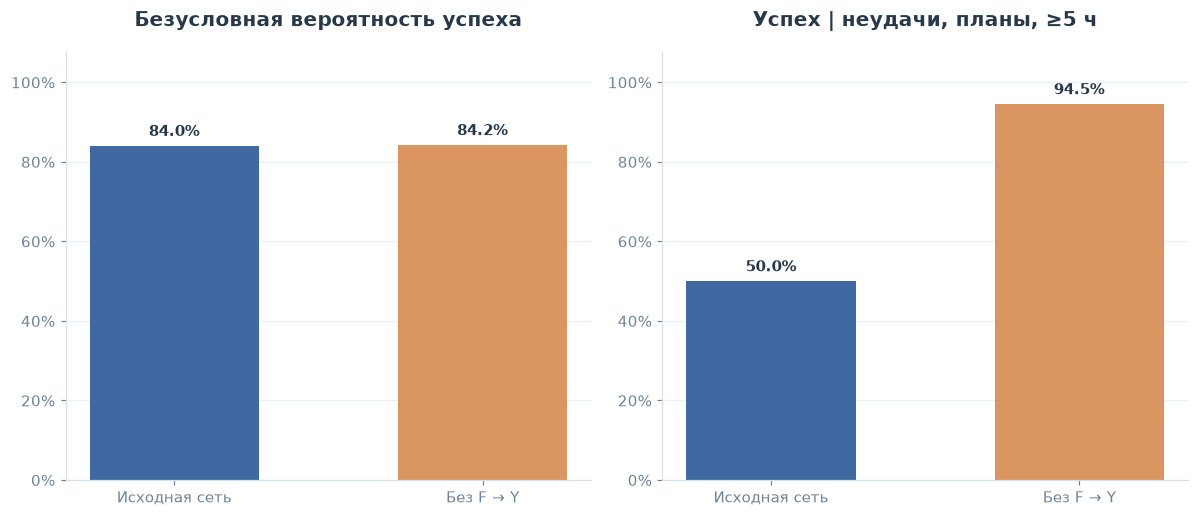

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for j, ax in enumerate(axes):
    vals = structure_result.iloc[:, j].to_numpy()
    bars = ax.bar([0, 1], vals, width=0.55, color=[COLORS['blue'], COLORS['orange']])
    for bar, value in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, value+0.025, f'{value:.1%}', ha='center', fontweight='bold')
    ax.set(xticks=[0, 1], xticklabels=['Исходная сеть', 'Без F → Y'], ylim=(0, 1.08),
           title=['Безусловная вероятность успеха', 'Успех | неудачи, планы, ≥5 ч'][j])
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y')
fig.tight_layout()
save_plot(fig, 'structure_comparison.png')

Направление стрелок нельзя уверенно выбрать только по этим наблюдениям. Разные DAG могут задавать одинаковые условные независимости (марковская эквивалентность); кроме того, неизвестные общие причины и ошибки анкет могут объяснять наблюдаемые связи. Этот эксперимент показывает чувствительность вывода к одному структурному предположению, но не доказывает истинность исходного графа.

## 9. Чувствительность к сглаживанию
Редкие родительские группы требуют отдельной проверки. Я повторил наиболее подробный запрос при α=0.5, 1 и 2. Чем меньше группа, тем сильнее априорное распределение влияет на результат. Это проверка чувствительности, а не доверительный интервал.

In [16]:
sensitivity = pd.DataFrame([
    {'alpha': a, 'P(успех | F=1,H=1,S=1)': query('passed', steps[-1][1],
        joint_distribution(parents, fit_cpts(data, parents, alpha=a)))[1],
     'P(успех | F=0,H=1,S=1)': query('passed', {'failures': 0, 'higher': 1, 'study': 1},
        joint_distribution(parents, fit_cpts(data, parents, alpha=a)))[1]}
    for a in [0.5, 1.0, 2.0]
])
show_table(sensitivity.round(4))
sensitivity.to_csv(ART / 'smoothing_sensitivity.csv', index=False)
metadata = {'source': 'https://archive.ics.uci.edu/static/public/320/student+performance.zip',
            'file': 'student-por.csv', 'sha256': hashlib.sha256((BASE / 'data/student-por.csv').read_bytes()).hexdigest(),
            'n': len(data), 'alpha': 1, 'parents': parents, 'states': {v: [0, 1] for v in nodes}}
(ART / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')

,alpha,"P(успех | F=1,H=1,S=1)","P(успех | F=0,H=1,S=1)"
0,0.500,0.500,0.979
1,1.000,0.500,0.975
2,2.000,0.500,0.967


690

### Устойчивость к выбору псевдосчётчика

Для наглядности я использовал отдельные шкалы: в сбалансированной группе ответ не меняется, а в группе с высокой долей успехов сглаживание сдвигает вероятность к 0.5.

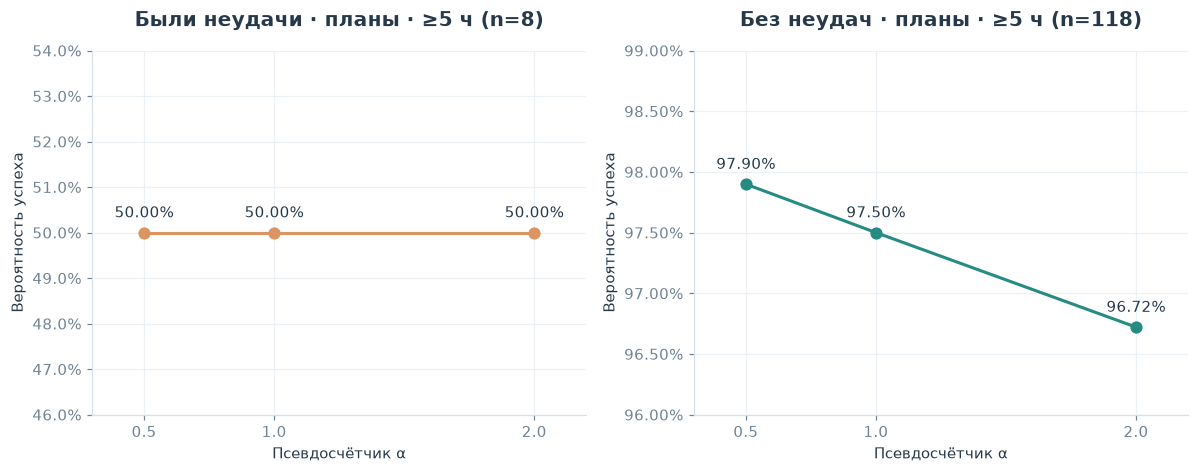

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for j, ax in enumerate(axes):
    vals = sensitivity.iloc[:, j+1]
    ax.plot(sensitivity.alpha, vals, 'o-', color=[COLORS['orange'], COLORS['teal']][j], lw=2, markersize=7)
    for a, value in zip(sensitivity.alpha, vals):
        ax.annotate(f'{value:.2%}', (a, value), xytext=(0, 10), textcoords='offset points', ha='center')
    ax.set(xlabel='Псевдосчётчик α', ylabel='Вероятность успеха', xticks=sensitivity.alpha,
           title=['Были неудачи · планы · ≥5 ч (n=8)', 'Без неудач · планы · ≥5 ч (n=118)'][j],
           ylim=[(0.46, 0.54), (0.96, 0.99)][j], xlim=(0.3, 2.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid()
fig.tight_layout()
save_plot(fig, 'smoothing_sensitivity.png')

В основном запросе вероятность остаётся 0.5 при всех трёх α: в этой группе ровно 4 успеха из 8, и симметричное сглаживание сохраняет долю 1/2. Это арифметическая симметрия, а не свидетельство точной оценки. Поэтому я также рассмотрел группу без прошлых неудач: там изменение α действительно меняет ответ.

## 10. Причинность и ограничения
**Я рассматриваю построенную сеть как описательную вероятностную модель.** Стрелки кодируют выбранную факторизацию и гипотезы о порядке зависимостей. Предшествование образования матери или прошлых неудач итоговой оценке поддерживает временную интерпретацию, но не устраняет смешение и не доказывает прямое воздействие.

`P(passed | study=1)` — распределение среди учеников с данным временем занятий. Оно не равно автоматически `P(passed | do(study=1))`: более мотивированные или, наоборот, испытывающие трудности ученики могут заниматься дольше. Результаты нельзя использовать как оценку эффекта вмешательства.

Ограничения: две школы и один предмет; самоотчёты; небольшой размер некоторых сочетаний; потеря информации после дискретизации; предположение независимости корней; пропущенные факторы; вручную выбранная структура; отсутствие проверки на внешней выборке и оценки неопределённости параметров. Сглаживание предотвращает нули, но не создаёт новые наблюдения. Таблицы описывают данный набор, переносимость на другие школы не проверялась.

## 11. Итоги

In [18]:
display(Markdown(
    f"Я построил сеть из **{len(nodes)} переменных** и **{sum(map(len, parents.values()))} рёбер** "
    f"и оценил её параметры по **{len(data)} наблюдениям**.\n\n"
    f"Наиболее заметной оказалась связь прошлых учебных неудач с итогом: вероятность успеха "
    f"снижается с **{query('passed')[1]:.1%}** до **{query('passed', {'failures': 1})[1]:.1%}**. "
    "При уточнении планов и времени занятий вероятность меняется немонотонно; "
    "для интерпретации таких изменений я учитывал численность групп.\n\n"
    f"После удаления прямого ребра от прошлых неудач подробный запрос изменился на "
    f"**{delta_structure:+.2f} п.п.**. Этот эксперимент показал, насколько результат зависит "
    "от заложенных в граф условных независимостей.\n\n"
    "Полученные оценки описывают выбранную совокупность учеников. Я не интерпретирую их "
    "как причинные эффекты или подтверждение качества прогноза в других школах."
))

Я построил сеть из **5 переменных** и **7 рёбер** и оценил её параметры по **649 наблюдениям**.

Наиболее заметной оказалась связь прошлых учебных неудач с итогом: вероятность успеха снижается с **84.0%** до **51.0%**. При уточнении планов и времени занятий вероятность меняется немонотонно; для интерпретации таких изменений я учитывал численность групп.

После удаления прямого ребра от прошлых неудач подробный запрос изменился на **+44.53 п.п.**. Этот эксперимент показал, насколько результат зависит от заложенных в граф условных независимостей.

Полученные оценки описывают выбранную совокупность учеников. Я не интерпретирую их как причинные эффекты или подтверждение качества прогноза в других школах.